# AirCast · Jaipur
Historical next-day PM2.5 forecasting. Run beside train.py and data/. If this notebook is opened alone in Colab, the first cell asks for AirCast-Jaipur-audited.zip (the complete project ZIP).
Uses model-estimated CAMS air quality; results are not validation against Jaipur sensors. Recorded training summary and chart are visible below.

In [ ]:
from pathlib import Path
import subprocess, os
if not Path("train.py").is_file() and not Path("aircast/train.py").is_file():
    subprocess.run(["git", "clone", "https://github.com/fr3ddykru3g3r/aircast-jaipur.git", "aircast"], check=True)
if not Path("train.py").is_file():
    os.chdir("aircast")


In [ ]:
from pathlib import Path
import os, zipfile
if not Path("train.py").is_file():
    if not Path("aircast/train.py").is_file():
        from google.colab import files
        uploaded = files.upload()  # Choose the complete AirCast source ZIP
        archive = next((n for n in uploaded if n.lower().endswith(".zip")), None)
        if archive is None: raise ValueError("Upload the complete project ZIP")
        with zipfile.ZipFile(archive) as bundle:
            root = Path.cwd().resolve()
            if any(root not in (root / n).resolve().parents for n in bundle.namelist()):
                raise ValueError("Unsafe archive path")
            bundle.extractall(root)
    os.chdir("aircast")
assert Path("data/jaipur_air.json").is_file(), "The source data folder is required"


In [1]:
%pip -q install -r requirements.txt

In [2]:
from train import run
experiment = run()

{
  "selected": "ridge",
  "counts": {
    "hourly": 26304,
    "daily": 1096,
    "usable": 1089,
    "train": 540,
    "validation": 184,
    "test": 365
  },
  "splits": {
    "train": {
      "start": "2023-01-08",
      "end": "2024-06-30"
    },
    "validation": {
      "start": "2024-07-01",
      "end": "2024-12-31"
    },
    "test": {
      "start": "2025-01-01",
      "end": "2025-12-31"
    }
  },
  "validation_mae": {
    "ridge": 6.673310512608043,
    "forest": 6.729765610624013
  },
  "metrics": {
    "persistence": {
      "mae": 7.391061643835617,
      "rmse": 10.335353101601287,
      "r2": 0.5693360054930816,
      "missed": 14,
      "false_alarms": 14,
      "caught": 16,
      "correct_clear": 321,
      "precision": 0.5333333333333333,
      "recall": 0.5333333333333333
    },
    "ridge": {
      "mae": 7.084692445220621,
      "rmse": 9.660966282796442,
      "r2": 0.6237044696574394,
      "missed": 15,
      "false_alarms": 7,
      "caught": 15,
      "co

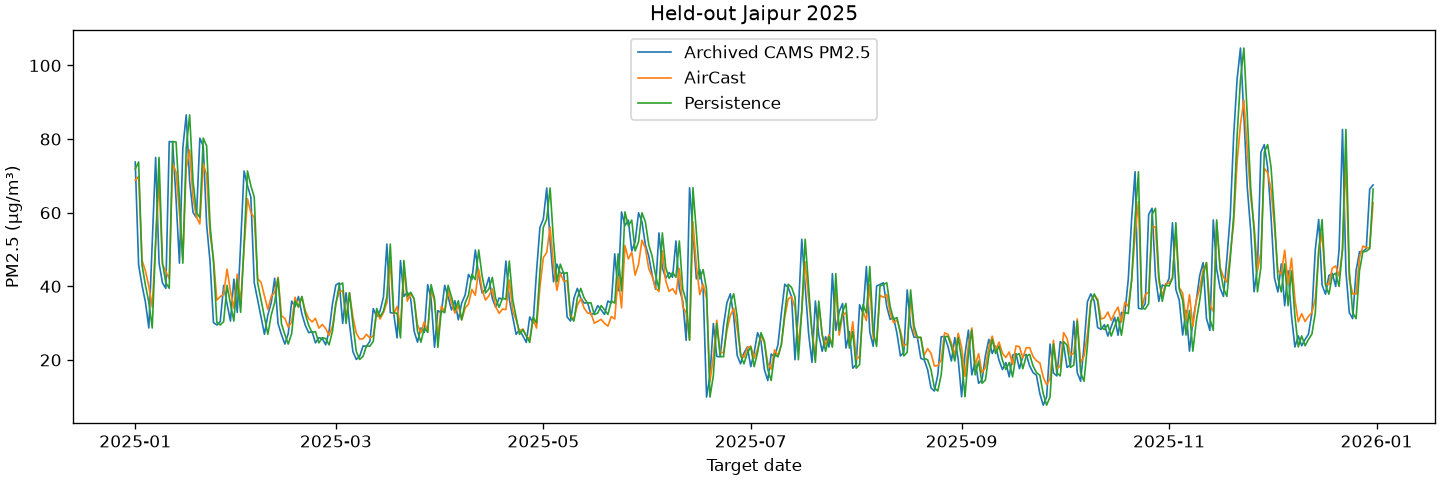

In [3]:
import pandas as pd
from matplotlib.figure import Figure
from IPython.display import display
p = pd.read_csv("dist/test_predictions.csv", parse_dates=["date"])
figure = Figure(figsize=(12, 4), layout="constrained")
ax = figure.subplots()
for key, label in [("actual_pm25", "Archived CAMS PM2.5"), (experiment["selected"], "AirCast"), ("persistence", "Persistence")]:
    ax.plot(p.date, p[key], label=label, linewidth=1)
ax.set(title="Held-out Jaipur 2025", ylabel="PM2.5 (µg/m³)", xlabel="Target date")
ax.legend()
display(figure)

In [ ]:
from verify import verify
audit = verify()

## Interpretation
Selection uses validation MAE only. Test data never trains or selects a model. Intervals use validation residuals and are empirical, not guaranteed. Reanalysis is retrospective and can contain revised information. Read README.md for failures, sources, and limitations.